In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.9"
os.environ["JAX_COMPILATION_CACHE_DIR"] = "/system/user/volkmann/jax_playground/jax_cache"

In [2]:
import jax
#jax.config.update("jax_enable_x64", True)  # Enable 64-bit precision
jax.config.update("jax_compilation_cache_dir", "/system/user/volkmann/jax_playground/jax_cache")
jax.config.update("jax_debug_nans", True)
from jax.experimental.compilation_cache import compilation_cache as cc
cc.set_cache_dir("/system/user/volkmann/jax_playground/jax_cache")

from matplotlib import pyplot as plt
import numpy as np
import autobound.jax as ab
import jax.numpy as jnp
import jax.random as jr
import optax
import equinox as eqx
from typing import Callable

from functools import partial
import k3d
import numpy as np
import math

In [3]:
from implicitSurfaces.jnpboundedImplicit import jnpboundedImplicit as autoboundedImplicit
import jnp_bounds as jnpb
from utils.jnpbounds_roots import roots_2nd_order_tensor
from rayMarcher.utils import ray_aabb_intersection_inside
from rayMarcher.sampler import generate_antialiased_ray, generate_random_unit_ray
from rayMarcher import utils


#### Neural Network

In [4]:
from typing import NamedTuple

class Params(NamedTuple):
    w1: jnp.ndarray  # [d_in, d_hidden]
    b1: jnp.ndarray  # [d_hidden]
    w2: jnp.ndarray  # [d_hidden, d_hidden]
    b2: jnp.ndarray  # [d_hidden]
    w3: jnp.ndarray  # [d_hidden, d_hidden]
    b3: jnp.ndarray  # [d_hidden]
    w4: jnp.ndarray  # [d_hidden, d_out]
    b4: jnp.ndarray  # [d_out]


def init_params(d_in, d_hidden, d_out, key):
    w1_key, w2_key, w3_key, w4_key, b1_key, b2_key, b3_key, b4_key = jax.random.split(key, num=8)
    return Params(
        w1=jax.random.uniform(key=w1_key, shape=[d_in, d_hidden], minval=-1/math.sqrt(d_in), maxval=1/math.sqrt(d_in)),
        b1=jax.random.uniform(key=b1_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w2=jax.random.uniform(key=w2_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b2=jax.random.uniform(key=b2_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w3=jax.random.uniform(key=w3_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b3=jax.random.uniform(key=b3_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w4=jax.random.uniform(key=w4_key, shape=[d_hidden, d_out], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b4=jax.random.uniform(key=b4_key, shape=[d_out], minval=-1/math.sqrt(d_out), maxval=1/math.sqrt(d_out)),
    )


def neural_network(params, x):
    x = x @ params.w1 + params.b1
    x = jax.nn.swish(x)
    x = x @ params.w2 + params.b2
    x = jax.nn.swish(x)
    x = x @ params.w3 + params.b3
    x = jax.nn.swish(x)
    x = x @ params.w4 + params.b4

    return x

#### Implicit definition

In [5]:
@partial(jax.jit, static_argnames=['radius'])
def sdf_sphere_jax(x: jnp.ndarray, radius: float) -> jnp.ndarray:
    return jnp.linalg.norm(x, axis=-1) - radius


@partial(jax.jit, static_argnames=['r', 'R'])
def sdf_torus_jax(x: jnp.ndarray, r: float, R: float) -> jnp.ndarray:
    q = jnp.sqrt(jnp.pow(x[0], 2) + jnp.pow(x[2], 2)) - R
    return jnp.sqrt(jnp.pow(q, 2) + jnp.pow(x[1], 2)) - r

def twistOperation(fn: Callable, k: float) -> Callable:
    @jax.jit
    def twist(x: jnp.array):
        c = jnp.cos(k * x[1])
        s = jnp.sin(k * x[1])
        m = jnp.array([[c, 0., -s], [s, 0., c], [0., 1., 0.]])
        return fn(jnp.matmul(m, x))
    return twist

#### Model fitting

In [6]:
def train(model, params, optim, ndim, gt_fn, n_steps, bbox, subkey):
    opt_state = optim.init(params)

    def loss_fn(params, X):
        pred_y = jax.vmap(model, in_axes=(None, 0))(params, X)
        true_y = jax.vmap(gt_fn)(X)
        return jnp.mean(jnp.pow((pred_y[:, 0] - true_y), 2))

    @jax.jit
    def step(params, opt_state, X):
        loss, grads = jax.value_and_grad(loss_fn, argnums=0)(params, X)
        update, opt_state = optim.update(grads, opt_state)
        params = optax.apply_updates(params, update)
        return params, opt_state, loss
    
    @jax.jit
    def point_sampler(key):
        key, subkey = jax.random.split(key)
        return jax.random.uniform(key, (10000, ndim), minval=bbox[0], maxval=bbox[1]), subkey

    for iter in range(0, n_steps):
        XY, subkey = point_sampler(subkey)
        params, opt_state, loss = step(params, opt_state, XY)
        if iter % 100 == 0:
            print(f"Iteration {iter}, loss: {loss}")
    return params

In [7]:
LEARNING_RATE = 1e-2
STEPS = 1000
RADIUS_OUTER = 0.5
RADIUS_INNER = 0.2
NDIM = 3
HIDDEN_DIM = 128

params = init_params(NDIM, HIDDEN_DIM, 1, key=jax.random.PRNGKey(1))
trained_params = init_params(NDIM, HIDDEN_DIM, 1, key=jax.random.PRNGKey(2))
optim = optax.adam(LEARNING_RATE)

In [8]:
trained_params = train(
    model=neural_network,
    params=params,
    optim=optim,
    ndim=NDIM,
    gt_fn=twistOperation(partial(sdf_torus_jax, r=RADIUS_INNER, R=RADIUS_OUTER), k=5.),
    n_steps=STEPS,
    bbox=(-1, 1),
    subkey=jax.random.PRNGKey(0)
)

Iteration 0, loss: 0.08659186959266663
Iteration 100, loss: 0.01814108155667782
Iteration 200, loss: 0.017566347494721413
Iteration 300, loss: 0.017184505239129066
Iteration 400, loss: 0.01708005554974079
Iteration 500, loss: 0.016074076294898987
Iteration 600, loss: 0.006853591650724411
Iteration 700, loss: 0.003077957546338439
Iteration 800, loss: 0.0023844444658607244
Iteration 900, loss: 0.0010479377815499902


### Marching Cubes

In [23]:
x0 = 0.0
offset = 1.0
level_set = 0.0


x_vals = jnp.linspace(x0 - offset, x0 + offset, 128)
y_vals = jnp.linspace(x0 - offset, x0 + offset, 128)
z_vals = jnp.linspace(x0 - offset, x0 + offset, 128)
X, Y, Z = jnp.meshgrid(x_vals, y_vals, z_vals)

grid_points = jnp.stack([X.ravel(), Y.ravel(), Z.ravel()], axis=-1)
fn_vals = jax.vmap(neural_network, in_axes=(None, 0))(trained_params, grid_points).reshape(X.shape)
#fn_vals = jax.vmap(twistOperation(partial(sdf_torus_jax, r=RADIUS_INNER, R=RADIUS_OUTER), k=5.))(grid_points).reshape(X.shape)
fn_vals_normalized = (fn_vals - jnp.min(fn_vals)) / (jnp.max(fn_vals) - jnp.min(fn_vals))
fn_vals_normalized_np = fn_vals_normalized.astype(np.float64)
level_set_normalized = (level_set - jnp.min(fn_vals)) / (jnp.max(fn_vals) - jnp.min(fn_vals))

/system/apps/userenv/volkmann/jax_env/lib/python3.14/site-packages/jax/_src/numpy/array_methods.py:125: UserWarning: Explicitly requested dtype <class 'numpy.float64'> requested in astype is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return lax_numpy.astype(self, dtype, copy=copy, device=device)


In [24]:
plot = k3d.plot()

iso_surf = k3d.marching_cubes(
    fn_vals_normalized_np, 
    level=level_set_normalized.astype(np.float32).item(),
    xmin=x0 - offset, xmax=x0 + offset,
    ymin=x0 - offset, ymax=x0 + offset,
    zmin=x0 - offset, zmax=x0 + offset,
    color=0x00ff00, 
    opacity=1.)
plot += iso_surf

In [25]:
plot.display()

Output()

## Rendering

In [35]:
from rayMarcher.integrator import Integrator
from rayMarcher.materials import Material
from rayMarcher.camera import Camera

camera_dict = {
    'image_width': 400,
    'image_height': 400,
    'defocus_angle': 0.0,
    'focus_distance': 1.0,
    'vfov': 90.0,
    'lookfrom': jnp.array([1.2, 0.0, 0.0]),
    'lookat': jnp.array([-1.2, 0., 0.]),
    'vup': jnp.array([0., 1.0, 0.0]),
}

In [36]:
def normal_at_point(point: jnp.ndarray) -> jnp.ndarray:
    grad_fn = jax.jacobian(ab_implicit.fn)
    normal = grad_fn(point)
    normal = normal / jnp.linalg.norm(normal)
    return normal.squeeze()

In [37]:
ab_implicit = autoboundedImplicit(lambda x: neural_network(trained_params, x), autobounds_max_degree=2, level_set=0.0, classification_flag='bernstein')

In [38]:
ab_intersec_batch_fn = ab_implicit.ray_surface_intersection_batch_fn(max_iterations=100, max_distance=10., init_interval=1.0, level_set_eps=1e-3, upper_lower_flag='lower')

In [39]:
camera = Camera.setup_Camera(**camera_dict)

normals_functions = [normal_at_point]

integrator = Integrator(
    camera=camera, materials={}, 
    background_color=jnp.array([0.5, 0.7, 1.0]),
    scene_intersection_batch_fn = ab_intersec_batch_fn,
    scene_dist_fns=[],
    scene_intersection_fn=None,
    scene_normal_fns=normals_functions,
    samples_per_pixel=1,
    max_depth=8,
    epsilon=1e-4,
    max_sphere_trace_dist=100.0,
)

In [40]:
key = jr.PRNGKey(42)

H, W = integrator.camera.image_height, integrator.camera.image_width
i_coords, j_coords = jnp.meshgrid(jnp.arange(W), jnp.arange(H))
i_coords = i_coords.flatten()
j_coords = j_coords.flatten()
pixel_keys = jr.split(key, H * W)

In [41]:
ray_origins, ray_directions = jax.vmap(generate_antialiased_ray, in_axes=(None, 0, 0, 0))(integrator.camera, i_coords, j_coords, pixel_keys)
unit_directions_background = utils.normalize(ray_directions)
ts = 0.5 * (unit_directions_background[:, 1] + 1.0)
background_colors = (1.0 - ts[:, None]) * jnp.array([1.0, 1.0, 1.0]) + ts[:, None] * integrator.background_color

In [42]:
for init_interval in [0.1, 0.3, 0.5, 0.7, 1.0, 1.5]:
    ab_intersec_batch_fn = ab_implicit.ray_surface_intersection_batch_fn(max_iterations=100, max_distance=10., init_interval=init_interval, level_set_eps=1e-3, upper_lower_flag='lower')
    niter, ray_points, hit_mask = ab_intersec_batch_fn(ray_origins, ray_directions)
    print(f"Init interval: {init_interval}, Number of iterations: {jnp.sum(niter)}")

KeyboardInterrupt: 

In [43]:
ab_intersec_batch_fn = ab_implicit.ray_surface_intersection_batch_fn(max_iterations=100, max_distance=10., init_interval=0.5, level_set_eps=1e-3, upper_lower_flag='lower')


In [44]:
niter, ray_points, hit_mask = ab_intersec_batch_fn(ray_origins, ray_directions)

W0120 12:54:49.076852 2963791 hlo_rematerialization.cc:3198] Can't reduce memory use below 10.05GiB (10797176266 bytes) by rematerialization; only reduced to 13.19GiB (14162079556 bytes), down from 14.75GiB (15842880196 bytes) originally
W0120 12:55:41.968355 2963791 bfc_allocator.cc:501] Allocator (GPU_0_bfc) ran out of memory trying to allocate 14.75GiB (rounded to 15842622208)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
W0120 12:55:41.968714 2963791 bfc_allocator.cc:512] *___________________________________________________________________________________________________
E0120 12:55:41.968736 2963791 pjrt_stream_executor_client.cc:3314] Execution of replica 0 failed: RESOURCE_EXHAUSTED: Out of memory while trying to allocate 15842621992 bytes. [tf-allocator-allocation-error='']


XlaRuntimeError: RESOURCE_EXHAUSTED: Out of memory while trying to allocate 15842621992 bytes.

In [ ]:
hit_normal = jax.vmap(integrator.scene_normal_fns[0])(ray_points)
test_color = jnp.clip(0.5 * hit_normal + jnp.array([1., 1., 1.]), 0.0, 1.0)
pixels_colors = jnp.where(hit_mask[:, None], test_color, background_colors)

In [ ]:
%timeit ab_intersec_batch_fn(ray_origins, ray_directions).niter.block_until_ready()  

1.23 s ± 2.54 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [ ]:
rendered_image_np = np.array(pixels_colors).reshape((H, W, 3))
n_steps_per_pixel = np.array(niter).reshape((H, W))

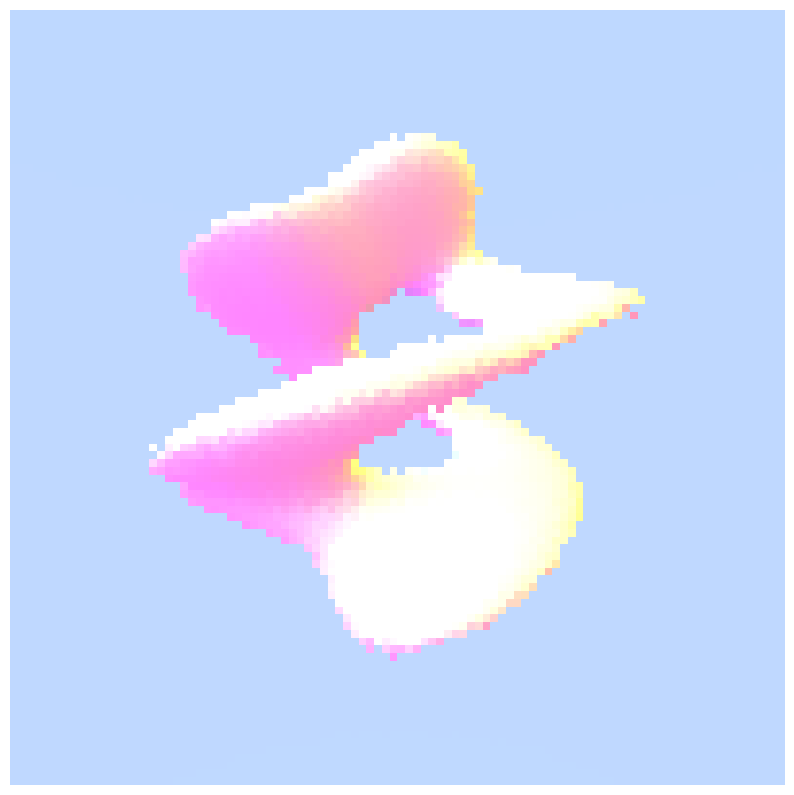

In [ ]:
plt.figure(figsize=(10, 15))
plt.imshow(rendered_image_np)
plt.axis('off')
plt.show()

In [24]:
%timeit jitted_render_sphere_trace(jax.random.PRNGKey(42))[0].block_until_ready()

3.85 s ± 492 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


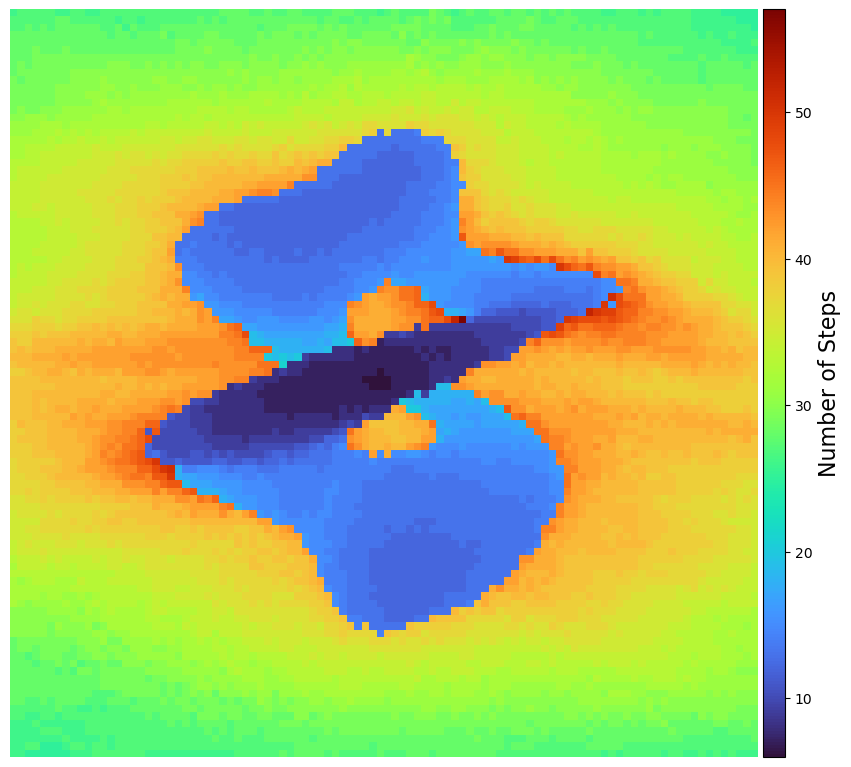

In [22]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, ax = plt.subplots(figsize=(10, 15))
im = ax.imshow(n_steps_per_pixel, cmap='turbo')
ax.axis('off')

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="3%", pad=0.05)  # colorbar width; height matches image
cb = plt.colorbar(im, cax=cax)
cb.set_label('Number of Steps', fontsize=16)

plt.show()

In [26]:
N_pixels = integrator.camera.image_width * integrator.camera.image_height


#### check jnpAutobounds

In [25]:
ray_origin = jnp.array([2.0, 0.0, 0.0])
ray_direction = jnp.array([1.0, 0.0, 0.0])
trust_region_size = jnp.array(1.0)

ray_origin_batch = jnp.tile(ray_origin, (10000, 1))
ray_direction_batch = jnp.tile(ray_direction, (10000, 1))

ab_implicit.ray_intersection_bounded(ray_origin, ray_direction, trust_region_size, upper_lower_flag='lower')

(Array(True, dtype=bool),
 Array([2.2017353, 0.       , 0.       ], dtype=float64),
 Array(0.2017353, dtype=float64),
 Array(0.5, dtype=float64),
 Array(1.75639264, dtype=float64))

In [19]:
ab_implicit.taylor_bounds(ray_origin, trust_region_size=trust_region_size, x_trust_region=None)

TaylorBounds(x0=Array([2., 0., 0.], dtype=float64), polynomial_enclosure=MixedIntervalPolynomial(real_coeffs=[[ 1.756]
 [-0.015]
 [-1.613]
 [ 2.06 ]], interval_coeffs=Interval(lower=[[-46200.797]
 [-18400.183]
 [-10303.816]
 [ -1675.456]
 [ -2663.97 ]
 [  -417.099]],
         upper=[[50866.332]
 [18309.947]
 [12342.507]
 [ 1693.894]
 [ 2715.455]
 [  510.629]])))

In [15]:
jit_interec = jax.jit(jax.vmap(ab_implicit.ray_intersection_lower_bound, in_axes=(0, 0, None)))
jit_interec(ray_origin_batch, ray_direction_batch, trust_region_size)

(Array([[ True],
        [ True],
        [ True],
        ...,
        [ True],
        [ True],
        [ True]], dtype=bool),
 Array([[0.02307553, 0.        , 0.        ],
        [0.02307553, 0.        , 0.        ],
        [0.02307553, 0.        , 0.        ],
        ...,
        [0.02307553, 0.        , 0.        ],
        [0.02307553, 0.        , 0.        ],
        [0.02307553, 0.        , 0.        ]], dtype=float64),
 Array([[0.02307553],
        [0.02307553],
        [0.02307553],
        ...,
        [0.02307553],
        [0.02307553],
        [0.02307553]], dtype=float64),
 Array([1., 1., 1., ..., 1., 1., 1.], dtype=float64),
 Array([[0.21479901],
        [0.21479901],
        [0.21479901],
        ...,
        [0.21479901],
        [0.21479901],
        [0.21479901]], dtype=float64))

In [16]:
tr = jnpb.types.Interval(jnp.array([2.0]), jnp.array([7.0]))
x0 = jnp.array([4.5])

jnpb.interval_arithmetic.subtract(tr, x0)

Interval(lower=[-2.5],
         upper=[2.5])

In [17]:
%timeit jit_interec(ray_origin_batch, ray_direction_batch, trust_region_size)

95.8 ms ± 4.26 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [22]:
ab_implicit.fn(ray_origin)

Array([0.21479901], dtype=float64)

In [19]:
lower_batch = jnp.ones_like(ray_direction_batch) - trust_region_size / 2
upper_batch = jnp.ones_like(ray_direction_batch) + trust_region_size / 2

In [24]:
def dummy_fn(ray, tr_size):
    return ab_implicit.taylor_bounds(ray, trust_region_size=tr_size, x_trust_region=None).polynomial_enclosure

def dummy2_fn(poly_encl):
    center_fn_val = poly_encl[0]
    taylor_enclosure = poly_encl
    upper_lower_flag = None

    if upper_lower_flag is None:
        upper_lower_flag = jnp.where(center_fn_val > 0.0, jnp.array(-1), jnp.array(1)).squeeze() # -1 for lower, 1 for upper
        
    #taylor_enclosure.real_coeffs = taylor_enclosure.real_coeffs.at[0].add(0.0)
    hit, t_poly_intersection = roots_2nd_order_tensor(taylor_enclosure, ray_direction, upper_lower_flag, dim=ray_origin.shape[0])
    ### check if point is within bounds
    t_box_intersection = ray_aabb_intersection_inside(ray_origin, ray_direction, trust_region_size)
    in_box = jnp.logical_and(hit, t_poly_intersection < t_box_intersection)
    t = jnp.where(in_box, t_poly_intersection, t_box_intersection)
    hit_point = ray_origin + t * ray_direction

    return in_box, hit_point, t, t_box_intersection, center_fn_val

def dummy_combine_fn(ray, tr_size):
    poly_encl = dummy_fn(ray, tr_size)
    return dummy2_fn(poly_encl)[1]

In [25]:
dummy_jit_vmap = jax.jit(jax.vmap(dummy_fn, in_axes=(0, None)))
poly_encl_batch = dummy_jit_vmap(ray_origin_batch, trust_region_size)

In [27]:
dummy2_fn_jit_vmap = jax.jit(jax.vmap(dummy2_fn, in_axes=(0,)))
dummy2_fn_jit_vmap(poly_encl_batch)

(Array([[False],
        [False],
        [False],
        ...,
        [False],
        [False],
        [False]], dtype=bool),
 Array([[1., 0., 0.],
        [1., 0., 0.],
        [1., 0., 0.],
        ...,
        [1., 0., 0.],
        [1., 0., 0.],
        [1., 0., 0.]], dtype=float64),
 Array([[1.],
        [1.],
        [1.],
        ...,
        [1.],
        [1.],
        [1.]], dtype=float64),
 Array([1., 1., 1., ..., 1., 1., 1.], dtype=float64),
 Array([[0.45053999],
        [0.45053999],
        [0.45053999],
        ...,
        [0.45053999],
        [0.45053999],
        [0.45053999]], dtype=float64))

In [26]:
dummy_combine_fn_jit_vmap = jax.jit(jax.vmap(dummy_combine_fn, in_axes=(0, None)))
dummy_combine_fn_jit_vmap(ray_origin_batch, trust_region_size)

Array([[0.02307553, 0.        , 0.        ],
       [0.02307553, 0.        , 0.        ],
       [0.02307553, 0.        , 0.        ],
       ...,
       [0.02307553, 0.        , 0.        ],
       [0.02307553, 0.        , 0.        ],
       [0.02307553, 0.        , 0.        ]], dtype=float64)

In [29]:
%timeit dummy_jit_vmap(ray_origin_batch, trust_region_size)[0].block_until_ready()

96.3 ms ± 29.7 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [20]:
%timeit dummy2_fn_jit_vmap(poly_encl_batch)[0].block_until_ready()

NameError: name 'dummy2_fn_jit_vmap' is not defined

In [46]:
%timeit dummy_combine_fn_jit_vmap(ray_origin_batch, trust_region_size)[0].block_until_ready()

96.4 ms ± 21.2 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [2]:
import jax
import jax.numpy as jnp
import numpy as np

def apply_interval_matvec(A, x_lo, x_hi, widen=True):
    """
    Applies point matrix A to interval vector [x_lo, x_hi] using the
    efficient Center-Radius method.
    
    Args:
        A: (M, N) Floating point matrix
        x_lo: (N,) Lower bound of input vector
        x_hi: (N,) Upper bound of input vector
        widen: If True, adds machine epsilon padding to ensure strict containment 
               despite floating point rounding errors.
    
    Returns:
        y_lo, y_hi: (M,) Lower and upper bounds of the result
    """
    # 1. Convert to Center-Radius representation
    # 0.5 multiplication is exact in float if exponents allow, but simple division is fine
    c = 0.5 * (x_lo + x_hi)
    r = 0.5 * (x_hi - x_lo)

    # 2. Apply Matrix (The Efficient Part)
    # We use standard high-performance matrix-vector multiplication
    y_c = jnp.dot(A, c)
    
    # For the radius, we must use the absolute value of A to correctly propagate
    # the interval width through negative weights.
    y_r = jnp.dot(jnp.abs(A), r)

    # 3. Handle Numerical Precision (Optional but recommended for rigor)
    if widen:
        # Calculate machine epsilon for the current dtype
        dtype = A.dtype
        finfo = jnp.finfo(dtype)
        eps = finfo.eps
        
        # We add a small padding proportional to the magnitude of the calculation
        # to cover rounding errors (ULPs) inherent in dot products.
        # Factor 10 is a heuristic safety margin; for strict interval arithmetic libraries 
        # this is often calculated more rigorously.
        padding = (jnp.abs(y_c) + y_r) * eps * 10
        y_r = y_r + padding

    # 4. Convert back to Endpoints
    y_lo = y_c - y_r
    y_hi = y_c + y_r
    
    return y_lo, y_hi

def test_interval_bounds():
    print(f"{'DType':<10} | {'Valid %':<10} | {'Mean Width':<15} | {'Status'}")
    print("-" * 55)

    # Test across different precisions
    dtypes = [jnp.float16, jnp.bfloat16, jnp.float32, jnp.float64]
    
    N, M = 256, 256  # Matrix dimensions
    num_samples = 1000 # Number of random vectors to sample for verification
    
    # Set random seed for reproducibility
    key = jax.random.PRNGKey(42)
    
    for dtype in dtypes:
        try:
            # Generate random matrix A
            key, subkey = jax.random.split(key)
            A = jax.random.normal(subkey, (M, N), dtype=dtype)
            
            # Generate random input interval bounds
            key, subkey = jax.random.split(key)
            bounds1 = jax.random.normal(subkey, (N,), dtype=dtype)
            key, subkey = jax.random.split(key)
            bounds2 = jax.random.normal(subkey, (N,), dtype=dtype)
            
            x_lo = jnp.minimum(bounds1, bounds2)
            # Ensure interval has some non-trivial width
            x_hi = jnp.maximum(bounds1, bounds2) + 0.1 
            
            # 1. Compute Interval Bounds using our function
            y_lo, y_hi = apply_interval_matvec(A, x_lo, x_hi, widen=True)
            
            # 2. Verification: Sample random points INSIDE the input interval
            # and check if their projection falls INSIDE the output interval.
            
            # Generate random mixing coefficients [0, 1]
            key, subkey = jax.random.split(key)
            t = jax.random.uniform(subkey, (num_samples, N), dtype=dtype)
            
            # Sample vectors: x_sample = lo + t * (hi - lo)
            x_samples = x_lo + t * (x_hi - x_lo)
            
            # Project samples: y = Ax
            # Note: Cast to float32 for verification to avoid double rounding issues 
            # obscuring the logic, or keep native to test strict adherence.
            # We keep native here.
            y_samples = jnp.dot(x_samples, A.T)
            
            # Check bounds: y_lo <= y_samples <= y_hi
            # We use a tiny tolerance for the check itself to handle comparison quirks
            # close to machine boundaries, though 'widen=True' should handle this.
            valid_lower = jnp.all(y_samples >= y_lo)
            valid_upper = jnp.all(y_samples <= y_hi)
            
            # Check individual violations to get a percentage
            violations = jnp.logical_or(y_samples < y_lo, y_samples > y_hi)
            violation_rate = jnp.mean(violations)
            valid_pct = (1.0 - violation_rate) * 100
            
            avg_width = jnp.mean(y_hi - y_lo)
            
            status = "PASS" if valid_pct == 100.0 else "FAIL"
            print(f"{dtype.__name__:<10} | {valid_pct:>9.4f}% | {avg_width:>15.4f} | {status}")
            
        except Exception as e:
            print(f"{dtype.__name__:<10} | ERROR: {e}")

# Run the test
test_interval_bounds()

DType      | Valid %    | Mean Width      | Status
-------------------------------------------------------
float16    |  100.0000% |        219.5000 | PASS
bfloat16   | ERROR: Unknown format code 'f' for object of type 'str'
float32    |  100.0000% |        238.5714 | PASS
float64    |  100.0000% |        267.0729 | PASS


/tmp/ipykernel_2958894/1570738411.py:70: UserWarning: Explicitly requested dtype <class 'jax.numpy.float64'>  is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  A = jax.random.normal(subkey, (M, N), dtype=dtype)
/tmp/ipykernel_2958894/1570738411.py:74: UserWarning: Explicitly requested dtype <class 'jax.numpy.float64'>  is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  bounds1 = jax.random.normal(subkey, (N,), dtype=dtype)
/tmp/ipykernel_2958894/1570738411.py:76: UserWarning: Explicitly requested dtype <class 'jax.numpy.float64'>  is not available, and will be truncated to dtype float32. To enable more dtypes, set the j